# Task 3: Player Monthly Spending Prediction (CPE 342 - Team ML009)

- **Objective:** Predict monthly spending (`spending_30d`) in THB.
- **Core Challenge:** Zero-inflated continuous target (~50% non-spenders).
- **Evaluation Metric:** Normalized Mean Absolute Error (NMAE)
  $$\text{NMAE} = \frac{1}{1 + \frac{\sum |y_i - \hat{y}_i|}{\sum y_i}}$$
- **Architecture:** Two-Stage Hurdle Model
  - Stage 1: Binary Classifier for spending probability $P(\text{will\_spend} = 1)$
  - Stage 2: Log-scale Regressor on spenders for spending amount $E[Y | Y > 0]$
  - Combination: $\hat{y} = P(\text{will\_spend} = 1) \times \text{expm1}(\hat{y}_{\log})$ with threshold tuning.

In [4]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, log_loss, mean_absolute_error

import lightgbm as lgb
import xgboost as xgb

SEED = 42
N_SPLITS = 5
EPSILON = 1e-6
np.random.seed(SEED)

## 1. Load Data & Environment Setup

In [5]:
# Auto-detect data directory across common workspace layouts
CANDIDATE_DIRS = [
    "../data/task3",
    "data/task3",
    "../../CPE342-Hackathon/03_regression",
    "../CPE342-Hackathon/03_regression",
    "."
]
DATA_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(os.path.join(d, "train.csv"))), "../data/task3")
print(f"Using DATA_DIR: {os.path.abspath(DATA_DIR)}")

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

ID_COL = "player_id" if "player_id" in train_df.columns else train_df.columns[0]
TARGET_COL = "spending_30d" if "spending_30d" in train_df.columns else [c for c in train_df.columns if c not in test_df.columns][0]

print(f"ID_COL: {ID_COL} | TARGET_COL: {TARGET_COL}")
print(f"Train shape: {train_df.shape} | Test shape: {test_df.shape}")

Using DATA_DIR: d:\WORK\STUDY\Y3\CPE342 MACHINE LEARNING\Project-ML\CPE342-Hackathon\03_regression
ID_COL: player_id | TARGET_COL: spending_30d
Train shape: (104000, 34) | Test shape: (25889, 33)


## 2. Target Analysis & Zero-Inflation Check

In [6]:
n_total = len(train_df)
n_zero = (train_df[TARGET_COL] == 0).sum()
n_spenders = (train_df[TARGET_COL] > 0).sum()

print(f"Total Players   : {n_total:,}")
print(f"Non-Spenders (=0): {n_zero:,} ({n_zero / n_total * 100:.2f}%)")
print(f"Spenders     (>0): {n_spenders:,} ({n_spenders / n_total * 100:.2f}%)")
print("\nSpender Target Summary (THB):")
display(train_df.loc[train_df[TARGET_COL] > 0, TARGET_COL].describe())

Total Players   : 104,000
Non-Spenders (=0): 50,049 (48.12%)
Spenders     (>0): 53,951 (51.88%)

Spender Target Summary (THB):


count     53951.000000
mean      20234.883892
std       40053.792318
min           0.090000
25%         623.075000
50%        2314.050000
75%       14453.365000
max      300000.000000
Name: spending_30d, dtype: float64

## 3. Data Preprocessing & Missing Value Imputation

In [7]:
# Extract raw features
feature_cols = [c for c in train_df.columns if c not in [ID_COL, TARGET_COL]]

X_train_raw = train_df[feature_cols].copy()
X_test_raw = test_df[feature_cols].copy()
y_train = train_df[TARGET_COL].copy()
y_train_binary = (y_train > 0).astype(int)

# Median Imputation strictly fitted on training set
imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=feature_cols)
X_test_imp = pd.DataFrame(imputer.transform(X_test_raw), columns=feature_cols)

assert X_train_imp.isna().sum().sum() == 0, "Found NaN in imputed train!"
assert X_test_imp.isna().sum().sum() == 0, "Found NaN in imputed test!"
print(f"Imputation complete. Total features: {len(feature_cols)}")

Imputation complete. Total features: 32


## 4. Feature Engineering (4 Feature Groups - 34 Features)

In [8]:
def create_spending_history_features(df):
    df = df.copy()
    hist = df["historical_spending"].fillna(0)
    prev = df["prev_month_spending"].fillna(0)
    n_tx = df["total_transactions"].fillna(0)
    atv = df["avg_transaction_value"].fillna(0)
    freq = df["purchase_frequency"].fillna(0)
    days_p = df["days_since_last_purchase"].fillna(0)
    age = df["account_age_days"].fillna(1)

    df["spending_momentum"] = prev / (hist + EPSILON)
    df["avg_spend_per_transaction"] = hist / (n_tx + EPSILON)
    df["purchase_intensity"] = freq * atv
    df["days_since_purchase_norm"] = days_p / (age + EPSILON)
    df["rfm_recency"] = -days_p
    df["rfm_frequency"] = freq
    df["rfm_monetary"] = hist
    df["log_historical_spending"] = np.log1p(hist.clip(lower=0))
    df["log_prev_month_spending"] = np.log1p(prev.clip(lower=0))
    df["log_avg_transaction_value"] = np.log1p(atv.clip(lower=0))
    return df

def create_engagement_features(df):
    df = df.copy()
    login_streak = df["daily_login_streak"].fillna(0)
    event_rate = df["event_participation_rate"].fillna(0)
    sessions_w = df["sessions_per_week"].fillna(0)
    avg_session = df["avg_session_length"].fillna(0)
    playtime = df["total_playtime_hours"].fillna(0)
    days_login = df["days_since_last_login"].fillna(999)
    age = df["account_age_days"].fillna(1)
    achiev_rate = df["achievement_completion_rate"].fillna(0)
    games_played = df["games_played"].fillna(0)
    cross_game = df["cross_game_activity"].fillna(0)

    df["engagement_score"] = 0.30 * login_streak + 0.40 * event_rate + 0.30 * sessions_w
    df["session_intensity"] = avg_session * sessions_w
    df["loyalty_score"] = age * (achiev_rate / 100.0)
    df["cross_game_ratio"] = cross_game / (games_played + EPSILON)
    df["daily_sessions"] = sessions_w / 7.0
    df["playtime_per_session"] = (playtime * 60) / (sessions_w * 30 + EPSILON)
    df["login_recency_flag"] = (days_login <= 3).astype(int)
    return df

def create_social_vip_features(df):
    df = df.copy()
    friends = df["friend_count"].fillna(0)
    vip = df["vip_status"].fillna(0)
    premium = df["is_premium_member"].fillna(0)
    guild = df["guild_membership"].fillna(0)
    social = df["social_interactions"].fillna(0)
    limited_ed = df["owns_limited_edition"].fillna(0)
    comp_rank = df["competitive_rank"].fillna(0)
    tourney = df["tournament_participation"].fillna(0)
    engagement = df.get("engagement_score", pd.Series(0, index=df.index))

    df["social_vip_score"] = friends * vip
    df["premium_x_engagement"] = premium * engagement
    df["guild_social"] = guild * social
    df["luxury_index"] = limited_ed * vip
    df["competitive_vip"] = comp_rank * vip
    df["social_density"] = social / (friends + EPSILON)
    df["tournament_vip"] = tourney * vip
    return df

def create_interaction_features(df):
    df = df.copy()
    vip = df["vip_status"].fillna(0)
    premium = df["is_premium_member"].fillna(0)
    hist = df["historical_spending"].fillna(0)
    seg = df["segment"].fillna(-1)
    freq = df["purchase_frequency"].fillna(0)
    n_tx = df["total_transactions"].fillna(0)
    disc_pct = df["purchases_on_discount"].fillna(0)

    df["vip_x_history"] = vip * hist
    df["premium_x_history"] = premium * hist
    for seg_id in [0, 1, 2, 3]:
        df[f"seg{seg_id}_x_history"] = (seg == seg_id).astype(float) * hist
    df["is_whale_segment"] = (seg == 3).astype(int)
    df["is_spender_segment"] = seg.isin([2, 3]).astype(int)
    df["vip_purchase_rate"] = vip * freq
    df["discount_sensitivity"] = disc_pct / (n_tx + EPSILON)
    return df

def apply_feature_engineering(df):
    df = create_spending_history_features(df)
    df = create_engagement_features(df)
    df = create_social_vip_features(df)
    df = create_interaction_features(df)
    return df

X_train_eng = apply_feature_engineering(X_train_imp)
X_test_eng = apply_feature_engineering(X_test_imp)

print(f"Original features: {X_train_imp.shape[1]}")
print(f"Engineered features: {X_train_eng.shape[1] - X_train_imp.shape[1]}")
print(f"Total features after FE: {X_train_eng.shape[1]}")

Original features: 32
Engineered features: 34
Total features after FE: 66


## 5. Metric Definition

In [9]:
def calculate_nmae(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    y_pred = np.clip(y_pred, 0, None)
    mae_sum = np.sum(np.abs(y_true - y_pred))
    y_true_sum = np.sum(y_true)
    if y_true_sum == 0:
        return 0.0
    return 1.0 / (1.0 + (mae_sum / y_true_sum))

## 6. Phase 4: Stage 1 Binary Classifier (Stratified 5-Fold)

In [10]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_stage1_lgb = np.zeros(len(train_df))
test_stage1_lgb = np.zeros(len(test_df))

oof_stage1_xgb = np.zeros(len(train_df))
test_stage1_xgb = np.zeros(len(test_df))

lgb_cls_params = {
    "objective": "binary",
    "metric": "binary_logloss",
    "boosting_type": "gbdt",
    "learning_rate": 0.03,
    "num_leaves": 31,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "n_estimators": 1000,
    "random_state": SEED,
    "n_jobs": -1,
    "verbose": -1
}

xgb_cls_params = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "learning_rate": 0.03,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "n_estimators": 1000,
    "random_state": SEED,
    "n_jobs": -1,
    "tree_method": "hist"
}

print("Training Stage 1 (Binary Classification) across 5 folds...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_eng, y_train_binary)):
    X_tr, y_tr = X_train_eng.iloc[train_idx], y_train_binary.iloc[train_idx]
    X_va, y_va = X_train_eng.iloc[val_idx], y_train_binary.iloc[val_idx]

    # LightGBM Classifier
    clf_lgb = lgb.LGBMClassifier(**lgb_cls_params)
    clf_lgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(50, verbose=False)])
    val_pred_lgb = clf_lgb.predict_proba(X_va)[:, 1]
    oof_stage1_lgb[val_idx] = val_pred_lgb
    test_stage1_lgb += clf_lgb.predict_proba(X_test_eng)[:, 1] / N_SPLITS

    # XGBoost Classifier
    clf_xgb = xgb.XGBClassifier(**xgb_cls_params)
    clf_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    val_pred_xgb = clf_xgb.predict_proba(X_va)[:, 1]
    oof_stage1_xgb[val_idx] = val_pred_xgb
    test_stage1_xgb += clf_xgb.predict_proba(X_test_eng)[:, 1] / N_SPLITS

    fold_auc_lgb = roc_auc_score(y_va, val_pred_lgb)
    fold_auc_xgb = roc_auc_score(y_va, val_pred_xgb)
    print(f"Fold {fold + 1} | LGB AUC: {fold_auc_lgb:.5f} | XGB AUC: {fold_auc_xgb:.5f}")

# Ensemble Stage 1
oof_stage1_prob = 0.5 * oof_stage1_lgb + 0.5 * oof_stage1_xgb
test_stage1_prob = 0.5 * test_stage1_lgb + 0.5 * test_stage1_xgb

stage1_auc = roc_auc_score(y_train_binary, oof_stage1_prob)
stage1_loss = log_loss(y_train_binary, oof_stage1_prob)
print(f"\nStage 1 Overall OOF AUC     : {stage1_auc:.5f}")
print(f"Stage 1 Overall OOF LogLoss : {stage1_loss:.5f}")

Training Stage 1 (Binary Classification) across 5 folds...
Fold 1 | LGB AUC: 0.78156 | XGB AUC: 0.77958
Fold 2 | LGB AUC: 0.78457 | XGB AUC: 0.78203
Fold 3 | LGB AUC: 0.78706 | XGB AUC: 0.78479
Fold 4 | LGB AUC: 0.78556 | XGB AUC: 0.78366
Fold 5 | LGB AUC: 0.78292 | XGB AUC: 0.78015

Stage 1 Overall OOF AUC     : 0.78399
Stage 1 Overall OOF LogLoss : 0.55399


## 7. Phase 5: Stage 2 Regressor (Trained on Spenders with log1p)

In [11]:
spender_mask = (y_train > 0)
X_train_spenders = X_train_eng[spender_mask].reset_index(drop=True)
y_train_spenders_raw = y_train[spender_mask].reset_index(drop=True)
y_train_spenders_log = np.log1p(y_train_spenders_raw)

print(f"Spender training rows: {len(X_train_spenders):,}")

kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_spenders_lgb = np.zeros(len(X_train_spenders))
test_stage2_lgb = np.zeros(len(test_df))

oof_spenders_xgb = np.zeros(len(X_train_spenders))
test_stage2_xgb = np.zeros(len(test_df))

lgb_reg_params = {
    "objective": "regression_l1",
    "metric": "mae",
    "boosting_type": "gbdt",
    "learning_rate": 0.03,
    "num_leaves": 31,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "n_estimators": 1000,
    "random_state": SEED,
    "n_jobs": -1,
    "verbose": -1
}

xgb_reg_params = {
    "objective": "reg:absoluteerror",
    "eval_metric": "mae",
    "learning_rate": 0.03,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "n_estimators": 1000,
    "random_state": SEED,
    "n_jobs": -1,
    "tree_method": "hist"
}

stage2_models = []

print("Training Stage 2 (Log Regressor on Spenders) across 5 folds...")
for fold, (train_idx, val_idx) in enumerate(kf.split(X_train_spenders)):
    X_tr, y_tr = X_train_spenders.iloc[train_idx], y_train_spenders_log.iloc[train_idx]
    X_va, y_va = X_train_spenders.iloc[val_idx], y_train_spenders_log.iloc[val_idx]

    # LightGBM Regressor
    reg_lgb = lgb.LGBMRegressor(**lgb_reg_params)
    reg_lgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(50, verbose=False)])
    val_pred_lgb = reg_lgb.predict(X_va)
    oof_spenders_lgb[val_idx] = val_pred_lgb
    test_stage2_lgb += reg_lgb.predict(X_test_eng) / N_SPLITS

    # XGBoost Regressor
    reg_xgb = xgb.XGBRegressor(**xgb_reg_params)
    reg_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    val_pred_xgb = reg_xgb.predict(X_va)
    oof_spenders_xgb[val_idx] = val_pred_xgb
    test_stage2_xgb += reg_xgb.predict(X_test_eng) / N_SPLITS

    stage2_models.append((reg_lgb, reg_xgb))
    print(f"Fold {fold + 1} | LGB Log MAE: {mean_absolute_error(y_va, val_pred_lgb):.4f} | XGB Log MAE: {mean_absolute_error(y_va, val_pred_xgb):.4f}")

# OOF Predictions for all players in Stage 2
oof_stage2_log = np.zeros(len(train_df))
for reg_lgb, reg_xgb in stage2_models:
    oof_stage2_log += (0.5 * reg_lgb.predict(X_train_eng) + 0.5 * reg_xgb.predict(X_train_eng)) / len(stage2_models)

test_stage2_log = 0.5 * test_stage2_lgb + 0.5 * test_stage2_xgb

oof_stage2_amount = np.expm1(oof_stage2_log)
test_stage2_amount = np.expm1(test_stage2_log)

spender_oof_mae = mean_absolute_error(y_train_spenders_raw, oof_stage2_amount[spender_mask])
print(f"\nStage 2 Spenders Only OOF MAE (THB): {spender_oof_mae:.2f}")

Spender training rows: 53,951
Training Stage 2 (Log Regressor on Spenders) across 5 folds...
Fold 1 | LGB Log MAE: 0.1544 | XGB Log MAE: 0.1473
Fold 2 | LGB Log MAE: 0.1497 | XGB Log MAE: 0.1454
Fold 3 | LGB Log MAE: 0.1479 | XGB Log MAE: 0.1425
Fold 4 | LGB Log MAE: 0.1503 | XGB Log MAE: 0.1434
Fold 5 | LGB Log MAE: 0.1468 | XGB Log MAE: 0.1430

Stage 2 Spenders Only OOF MAE (THB): 3041.25


## 8. Hurdle Model Combination & Probability Threshold Tuning

In [12]:
# Hurdle Prediction Formula: P(will_spend) * amount_prediction
baseline_oof_pred = oof_stage1_prob * oof_stage2_amount
baseline_nmae = calculate_nmae(y_train, baseline_oof_pred)
print(f"Baseline Two-Stage OOF NMAE: {baseline_nmae:.5f}")

# Probability threshold optimization to maximize NMAE
best_threshold = 0.50
best_nmae = baseline_nmae

candidate_thresholds = np.linspace(0.15, 0.70, 56)
for th in candidate_thresholds:
    pred_th = np.where(oof_stage1_prob >= th, oof_stage1_prob * oof_stage2_amount, 0.0)
    nmae_th = calculate_nmae(y_train, pred_th)
    if nmae_th > best_nmae:
        best_nmae = nmae_th
        best_threshold = th

print(f"Optimized Probability Threshold: {best_threshold:.4f}")
print(f"Optimized Two-Stage OOF NMAE   : {best_nmae:.5f} (Improvement: {best_nmae - baseline_nmae:+.5f})")

oof_final_pred = np.where(oof_stage1_prob >= best_threshold, oof_stage1_prob * oof_stage2_amount, 0.0)
test_final_pred = np.where(test_stage1_prob >= best_threshold, test_stage1_prob * test_stage2_amount, 0.0)
test_final_pred = np.clip(test_final_pred, 0, None)

Baseline Two-Stage OOF NMAE: 0.79376
Optimized Probability Threshold: 0.4800
Optimized Two-Stage OOF NMAE   : 0.79494 (Improvement: +0.00117)


## 9. Submission Generation

In [13]:
EXPECTED_TEST_ROWS = 25889
assert len(test_final_pred) == EXPECTED_TEST_ROWS, f"Expected {EXPECTED_TEST_ROWS} predictions, got {len(test_final_pred)}"
assert not np.isnan(test_final_pred).any(), "Found NaN in final predictions!"
assert (test_final_pred >= 0).all(), "Found negative spending in predictions!"

# Submission DataFrame format aligned with sample_submission.csv
sub_df = pd.DataFrame({
    "id": test_df[ID_COL],
    "task3": test_final_pred
})

# Export to submissions directory
sub_dirs = ["../submissions", "submissions", "../../submissions"]
target_sub_dir = next((d for d in sub_dirs if os.path.exists(d)), "../submissions")
os.makedirs(target_sub_dir, exist_ok=True)

sub_path = os.path.join(target_sub_dir, "sub_task3.csv")
sub_df.to_csv(sub_path, index=False)

print(f"Successfully saved Task 3 predictions to {os.path.abspath(sub_path)}")
print(f"Row count: {len(sub_df):,}")
print(f"Predicted non-zero spenders: {(sub_df['task3'] > 0).sum():,} ({(sub_df['task3'] > 0).mean() * 100:.2f}%)")
print("\nFirst 5 rows of submission:")
display(sub_df.head())

Successfully saved Task 3 predictions to d:\WORK\STUDY\Y3\CPE342 MACHINE LEARNING\Project-ML\CPE342-Hackathon\03_regression\submissions\sub_task3.csv
Row count: 25,889
Predicted non-zero spenders: 12,972 (50.11%)

First 5 rows of submission:


,id,task3
0,P030374,0.000000
1,P113216,1679.059929
2,P015351,0.000000
3,P095374,0.000000
4,P059369,0.000000


# Phase 10: Visualizations for Technical Report

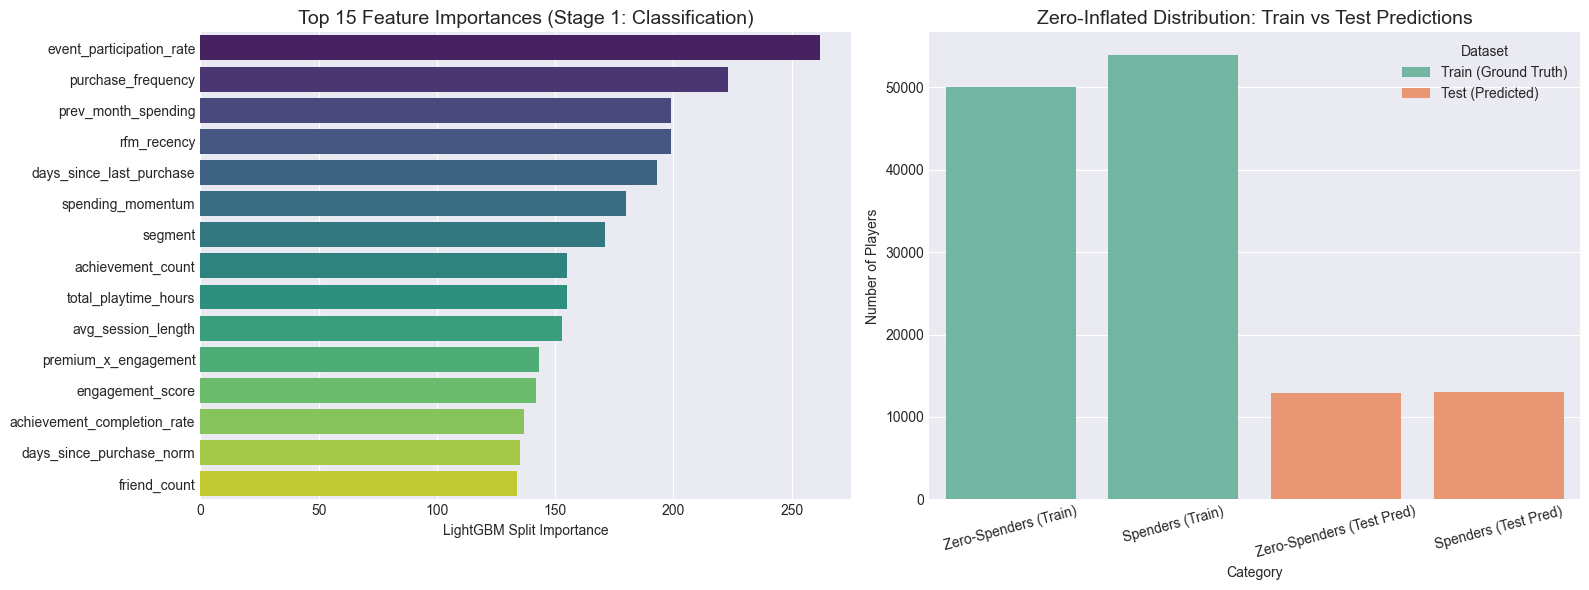

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-darkgrid')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Feature Importance (from LightGBM Stage 1)
# Assuming clf_lgb is the last trained LightGBM classifier from the fold loop
importance_df = pd.DataFrame({
    'Feature': X_train_eng.columns,
    'Importance': clf_lgb.feature_importances_
}).sort_values(by='Importance', ascending=False).head(15)

sns.barplot(data=importance_df, x='Importance', y='Feature', ax=axes[0], palette='viridis')
axes[0].set_title("Top 15 Feature Importances (Stage 1: Classification)", fontsize=14)
axes[0].set_xlabel("LightGBM Split Importance")
axes[0].set_ylabel("")

# 2. Prediction Distribution (Zero vs Spenders)
# Comparing Train Ground Truth vs Test Predictions
dist_df = pd.DataFrame({
    'Category': ['Zero-Spenders (Train)', 'Spenders (Train)', 'Zero-Spenders (Test Pred)', 'Spenders (Test Pred)'],
    'Count': [
        (y_train == 0).sum(), 
        (y_train > 0).sum(), 
        (test_final_pred == 0).sum(), 
        (test_final_pred > 0).sum()
    ],
    'Dataset': ['Train (Ground Truth)', 'Train (Ground Truth)', 'Test (Predicted)', 'Test (Predicted)']
})

sns.barplot(data=dist_df, x='Category', y='Count', hue='Dataset', ax=axes[1], palette='Set2')
axes[1].set_title("Zero-Inflated Distribution: Train vs Test Predictions", fontsize=14)
axes[1].set_ylabel("Number of Players")
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()